In [1]:
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_csv('Fashion_Trends.csv')

In [3]:
df

,Brand,Description,Product_ID,Discount_Price,Original_Price,Gender,Category,Discounted_amount,Discount_Percentage,Product_Name,Price_Segment,Discount_Tier
0,performax,Typographic Print Track Pants with Insert Pockets,441136763008,974,1299,Men,Activewear,325,25.02,Track Pants,Mid (₹500–₹1499),Moderate (20-40%)
1,performax,Low-Top Lace-Up Sports Shoes,450137679013,1499,1499,Men,Activewear,0,0.00,Sports Shoes,Mid (₹500–₹1499),No Discount
2,teamspirit,Colorblock Crew-Neck T-shirt,441133214008,461,549,Men,Activewear,88,16.03,Crew-Neck T-shirt,Mid (₹500–₹1499),Light (10-20%)
3,performax,Camouflage Print Joggers with Insert Pockets,441134776020,1189,1699,Men,Activewear,510,30.02,Print Joggers,Premium (₹1500–₹3999),Moderate (20-40%)
4,teamspirit,Reflective Colourblock Crew-Neck T-shirt,441136539020,425,599,Men,Activewear,174,29.05,Crew-Neck T-shirt,Mid (₹500–₹1499),Moderate (20-40%)
...,...,...,...,...,...,...,...,...,...,...,...,...
31577,ajio,Printed Top with Raglan Sleeves,460328028004,1299,1299,Women,Westernwear,0,0.00,Printed Top,Mid (₹500–₹1499),No Discount
31578,ajio,Striped Cropped Pants with Belt,460328036004,2099,2099,Women,Westernwear,0,0.00,Cropped Pants,Premium (₹1500–₹3999),No Discount
31579,ajio,Striped City Shorts with Belt,460328005002,1499,1499,Women,Westernwear,0,0.00,City Shorts,Mid (₹500–₹1499),No Discount
31580,ajio,Denim Jacket with Frayed Hemline,460328651009,2999,2999,Women,Westernwear,0,0.00,Denim Jacket,Premium (₹1500–₹3999),No Discount


In [6]:
#1. Data Preparation:
df.isnull().sum()

Brand                  0
Description            0
Product_ID             0
Discount_Price         0
Original_Price         0
Gender                 0
Category               0
Discounted_amount      0
Discount_Percentage    0
Product_Name           0
Price_Segment          0
Discount_Tier          0
dtype: int64

In [7]:
df.dtypes

Brand                   object
Description             object
Product_ID               int64
Discount_Price           int64
Original_Price           int64
Gender                  object
Category                object
Discounted_amount        int64
Discount_Percentage    float64
Product_Name            object
Price_Segment           object
Discount_Tier           object
dtype: object

In [8]:
df.columns

Index(['Brand', 'Description', 'Product_ID', 'Discount_Price',
       'Original_Price', 'Gender', 'Category', 'Discounted_amount',
       'Discount_Percentage', 'Product_Name', 'Price_Segment',
       'Discount_Tier'],
      dtype='object')

In [9]:
#2. Exploratory Data Analysis (EDA):
df.describe()

,Product_ID,Discount_Price,Original_Price,Discounted_amount,Discount_Percentage
count,3.158200e+04,31582.000000,31582.000000,31582.000000,31582.000000
mean,4.439001e+11,929.759832,1418.094769,488.334938,32.979031
std,5.715579e+09,727.207471,945.684511,544.062245,24.667178
min,4.200088e+11,75.000000,149.000000,0.000000,0.000000
25%,4.411142e+11,479.000000,799.000000,0.000000,0.000000
50%,4.411360e+11,735.000000,1299.000000,356.000000,35.040000
75%,4.501273e+11,1199.000000,1799.000000,749.000000,50.930000
max,4.608526e+11,16999.000000,19999.000000,11999.000000,85.010000


In [10]:
df.value_counts().sum()

31582

In [37]:
o = df.Original_Price.value_counts()
o

Original_Price
999     2824
1499    2660
1299    2590
699     2146
799     2026
        ... 
1675       1
224        1
185        1
825        1
1320       1
Name: count, Length: 313, dtype: int64

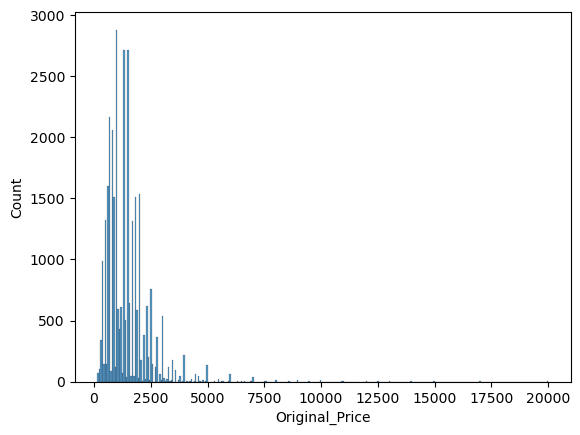

In [39]:
sb.histplot(df.Original_Price)
plt.show()

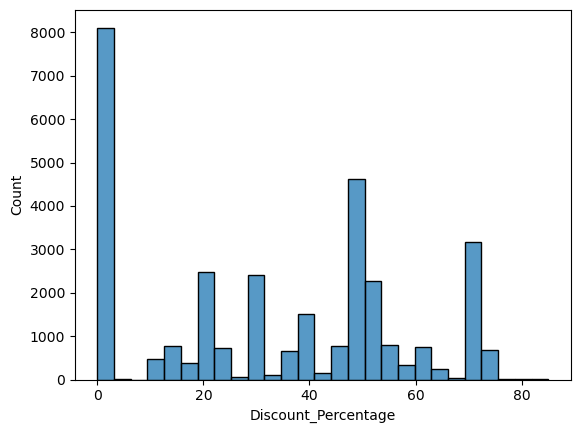

In [13]:
sb.histplot(df.Discount_Percentage)
plt.show()

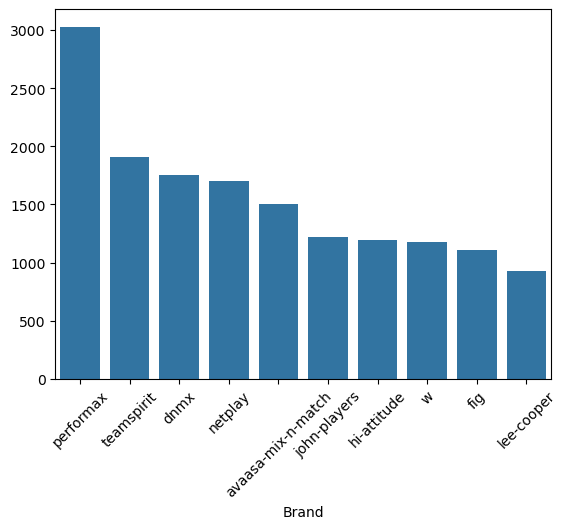

In [11]:
#barchart
b= df['Brand'].value_counts().nlargest(10)

sb.barplot(x=b.index, y =b.values)
plt.xticks(rotation=45)
plt.show()

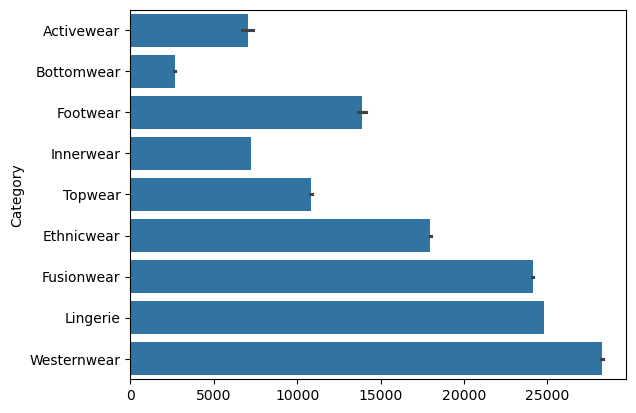

In [14]:
sb.barplot(df.Category)
plt.show()

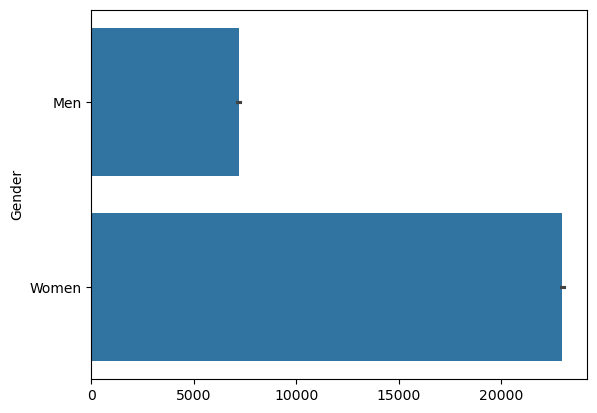

In [15]:
sb.barplot(df.Gender)
plt.show()

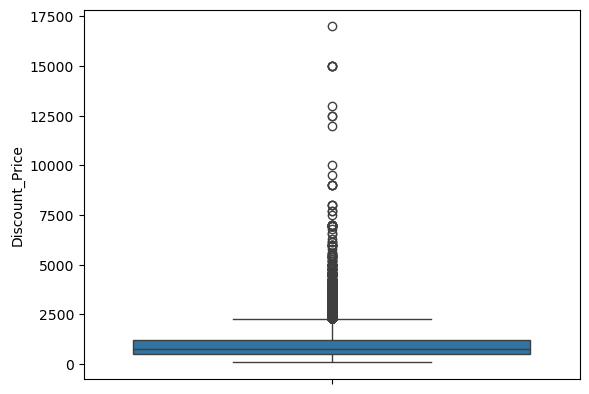

In [12]:
#outlayers
sb.boxplot(df.Discount_Price)
plt.show()

In [94]:
p='Discount_Price'

q1= np.percentile(df[p],25)
q3=np.percentile(df[p],75)

iqr=q3-q1

c1=q1-1.5*(iqr)
c2=q3+1.5*(iqr)

print(q1)
print(q3)
print(iqr)
print(c1)
print(c2)

400.0
799.0
399.0
-198.5
1397.5


In [95]:
t=df[(df[p]>c2) | (df[p]<c1) ]
t=t.index
df=df.drop(labels=t)
t

Index([  370,   730,   801,   897,   939,   975,  1004,  1066,  1482,  1664,
       ...
       30882, 30883, 30936, 30941, 30967, 30969, 31032, 31045, 31138, 31376],
      dtype='int64', length=331)

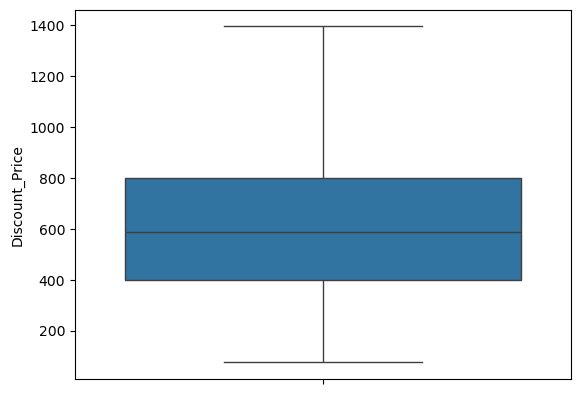

In [96]:
sb.boxplot(df.Discount_Price)
plt.show()

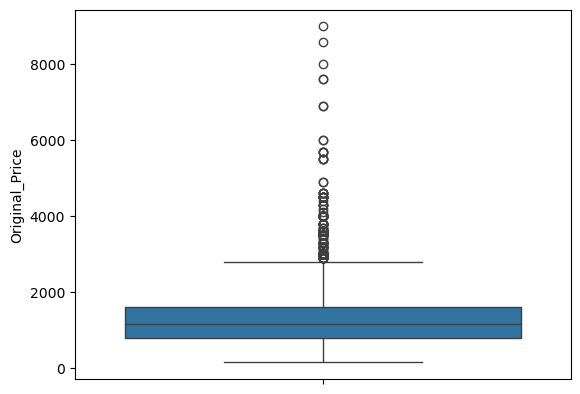

In [70]:
sb.boxplot(df.Original_Price)
plt.show()

In [68]:
o='Original_Price'

q1= np.percentile(df[o],25)
q3=np.percentile(df[o],75)

iqr=q3-q1

c1=q1-1.5*(iqr)
c2=q3+1.5*(iqr)

print(q1)
print(q3)
print(iqr)
print(c1)
print(c2)


799.0
1599.0
800.0
-401.0
2799.0


In [97]:
t=df[(df[o]>c2) | (df[o]<c1) ]
t=t.index
df=df.drop(labels=t)
t

Index([    3,    13,    37,    47,    54,    66,    73,    80,    82,    88,
       ...
       31465, 31466, 31467, 31471, 31472, 31488, 31491, 31492, 31544, 31554],
      dtype='int64', length=4577)

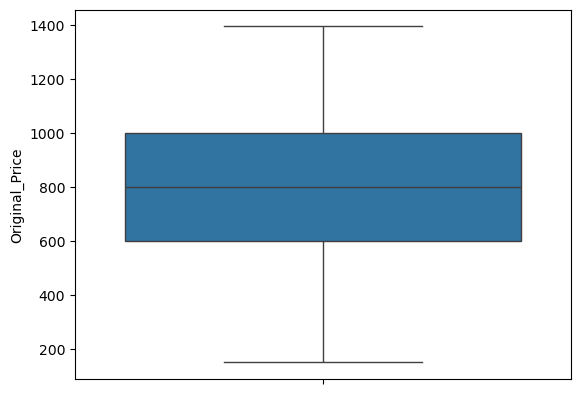

In [98]:
sb.boxplot(df.Original_Price)
plt.show()

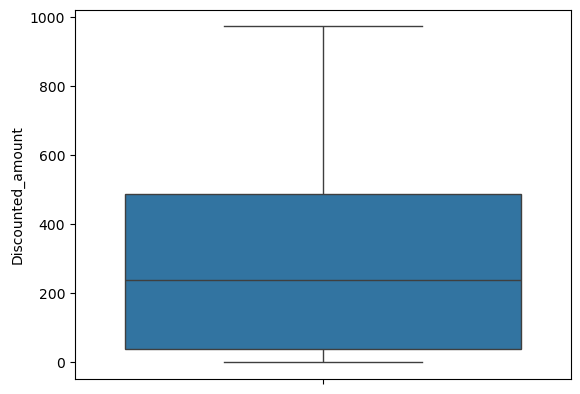

In [99]:
sb.boxplot(df.Discounted_amount)
plt.show()

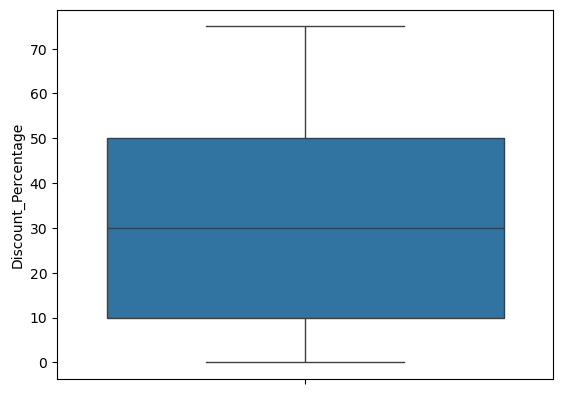

In [100]:
sb.boxplot(df.Discount_Percentage)
plt.show()

In [41]:
#Brand & Category Analysis:
b= df['Brand'].value_counts().nlargest(10)
b

Brand
performax             3029
teamspirit            1908
dnmx                  1757
netplay               1698
avaasa-mix-n-match    1507
john-players          1224
hi-attitude           1191
w                     1179
fig                   1110
lee-cooper             927
Name: count, dtype: int64

In [43]:
c= df['Category'].value_counts()
c

Category
Topwear        7110
Westernwear    6641
Footwear       6030
Ethnicwear     5265
Bottomwear     2984
Activewear     2134
Fusionwear      997
Lingerie        325
Innerwear        96
Name: count, dtype: int64

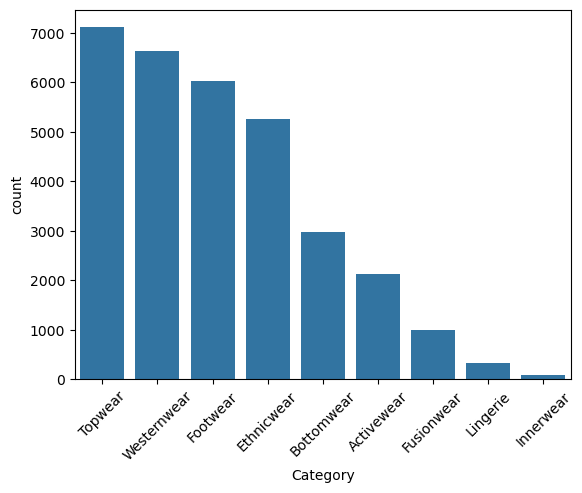

In [44]:
sb.barplot(c)
plt.xticks(rotation=45)
plt.show()

In [47]:
u= df.groupby('Price_Segment')['Category'].size()
u

Price_Segment
Low (<₹500)               2972
Luxury (₹4000+)            501
Mid (₹500–₹1499)         18237
Premium (₹1500–₹3999)     9872
Name: Category, dtype: int64

In [48]:
pd.crosstab(df['Category'],df['Price_Segment'])

Price_Segment,Low (<₹500),Luxury (₹4000+),Mid (₹500–₹1499),Premium (₹1500–₹3999)
Category,,,,
Activewear,156,9,1237,732
Bottomwear,79,3,1414,1488
Ethnicwear,588,227,2506,1944
Footwear,725,182,2766,2357
Fusionwear,25,61,532,379
Innerwear,83,0,11,2
Lingerie,153,0,171,1
Topwear,515,15,4989,1591
Westernwear,648,4,4611,1378


In [21]:
#Product Type Analysis:
df.Product_Name.value_counts().nlargest(10)

Product_Name
Crew-Neck T-shirt         2312
Fit Shirt                 2105
Straight Kurta            2053
Polo T-shirt              1125
A-line Kurta               751
Sports Shoes               727
Fit Jeans                  710
Flat Sandals               529
Thong-Strap Flip-Flops     515
Running Shoes              436
Name: count, dtype: int64

In [18]:
g=df.groupby('Gender')['Product_Name'].count()
g

Gender
Men      14375
Women    17207
Name: Product_Name, dtype: int64

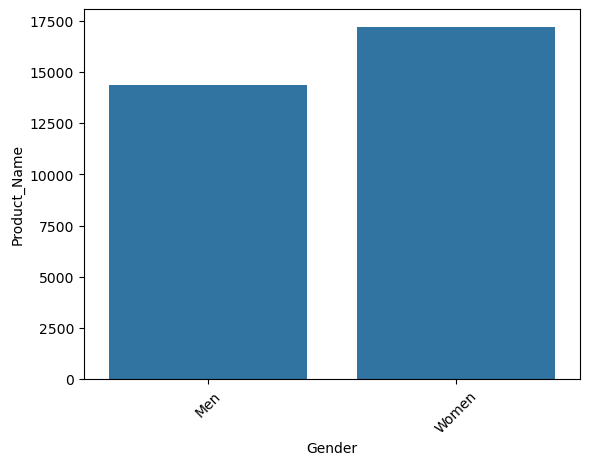

In [19]:
sb.barplot(g)
plt.xticks(rotation= 45)
plt.show()

In [21]:
df.groupby('Category')['Product_Name'].count().sort_values(ascending=False).head(10)

Category
Topwear        7110
Westernwear    6641
Footwear       6030
Ethnicwear     5265
Bottomwear     2984
Activewear     2134
Fusionwear      997
Lingerie        325
Innerwear        96
Name: Product_Name, dtype: int64

In [22]:
#Discount Analysis:
df.groupby('Discount_Tier').count()

,Brand,Description,Product_ID,Discount_Price,Original_Price,Gender,Category,Discounted_amount,Discount_Percentage,Product_Name,Price_Segment
Discount_Tier,,,,,,,,,,,
No Discount,8107,8107,8107,8107,8107,8107,8107,8107,8107,8107,8107
Deep (>40%),15194,15194,15194,15194,15194,15194,15194,15194,15194,15194,15194
Light (10-20%),1621,1621,1621,1621,1621,1621,1621,1621,1621,1621,1621
Moderate (20-40%),6660,6660,6660,6660,6660,6660,6660,6660,6660,6660,6660


In [25]:
df.groupby('Product_Name')['Discount_Percentage'].mean().nlargest()

Product_Name
Brocade Angarakha    80.00
Brocade Tunic        80.00
Chanderi Kurta       79.99
Chanderi Top         79.99
Black Cardigan       74.99
Name: Discount_Percentage, dtype: float64

In [49]:
pi=pd.pivot_table(data=df,index='Category',columns='Discount_Tier' ,values='Product_ID',margins=True)
pi

Discount_Tier,No Discount,Deep (>40%),Light (10-20%),Moderate (20-40%),All
Category,,,,,
Activewear,4.476286e+11,4.481564e+11,4.415876e+11,4.438992e+11,4.466264e+11
Bottomwear,4.426044e+11,4.427316e+11,4.411682e+11,4.411176e+11,4.422704e+11
Ethnicwear,4.424548e+11,4.420847e+11,4.410831e+11,4.411284e+11,4.420071e+11
Footwear,4.509148e+11,4.505169e+11,4.501281e+11,4.510030e+11,4.508539e+11
Fusionwear,4.456238e+11,4.414913e+11,NaN,4.411156e+11,4.426278e+11
Innerwear,4.399345e+11,4.409707e+11,NaN,4.411219e+11,4.400735e+11
Lingerie,4.410454e+11,4.410851e+11,NaN,4.399655e+11,4.405202e+11
Topwear,4.418112e+11,4.413974e+11,4.411778e+11,4.411302e+11,4.414040e+11
Westernwear,4.430364e+11,4.420095e+11,4.411822e+11,4.412466e+11,4.420273e+11


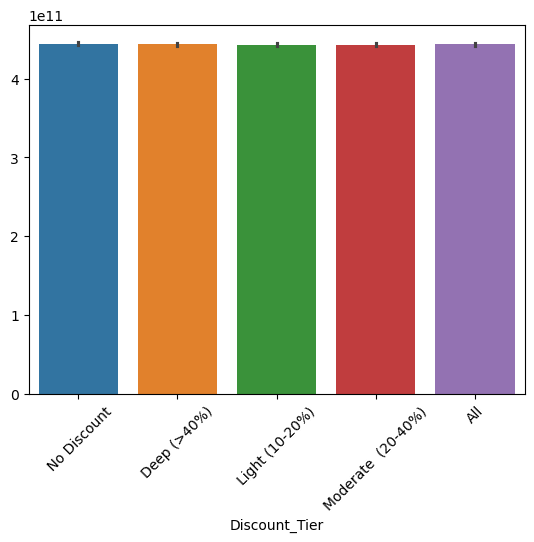

In [50]:
sb.barplot(pi)
plt.xticks(rotation = 45)
plt.show()

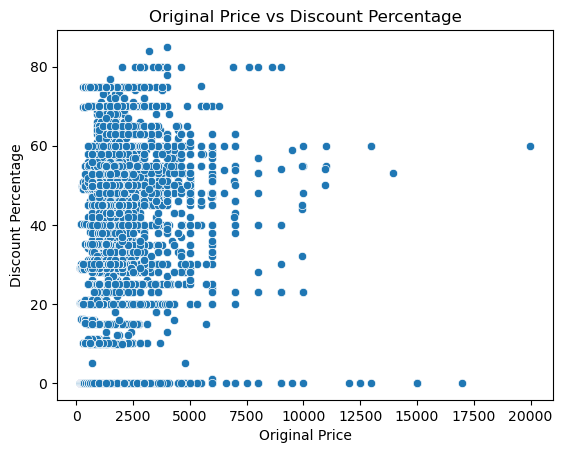

In [28]:
sb.scatterplot(data=df, x='Original_Price', y='Discount_Percentage')
plt.title('Original Price vs Discount Percentage')
plt.xlabel('Original Price')
plt.ylabel('Discount Percentage')
plt.show()

In [29]:
# Gender-Based Preferences:
df.groupby('Gender')['Category'].count()

Gender
Men      14375
Women    17207
Name: Category, dtype: int64

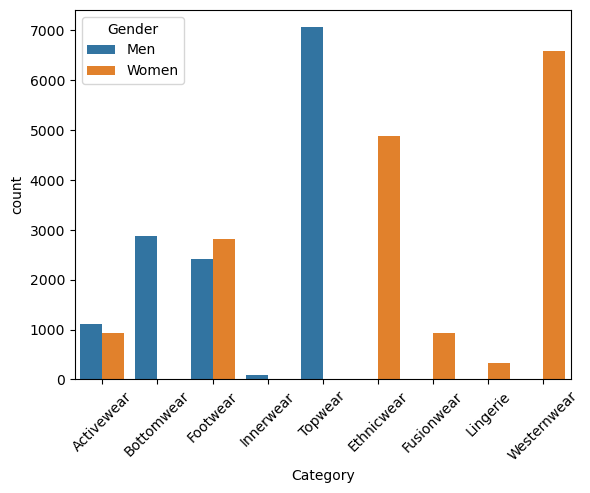

In [39]:
sb.countplot(data=df, x='Category',hue='Gender')
plt.xticks(rotation=45)
plt.show()

In [43]:
df.groupby('Gender')['Discount_Percentage'].mean()

Gender
Men      34.882795
Women    33.495226
Name: Discount_Percentage, dtype: float64

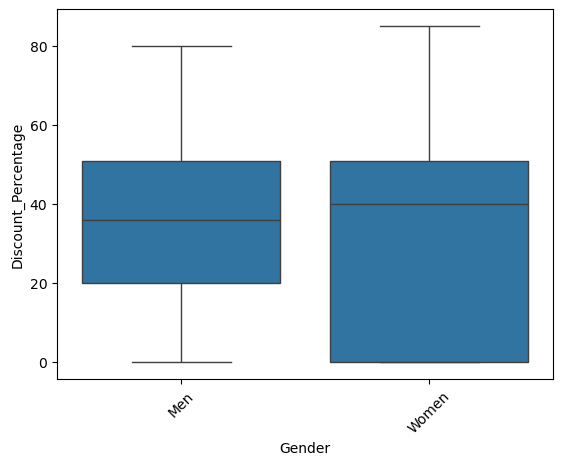

In [46]:
sb.boxplot(data = df , x='Gender',y= 'Discount_Percentage')
plt.xticks(rotation=45)
plt.show()

In [47]:
#Price Segment Analysis:

df.Price_Segment.value_counts()

Price_Segment
Mid (₹500–₹1499)         18237
Premium (₹1500–₹3999)     8685
Low (<₹500)               2972
Luxury (₹4000+)            152
Name: count, dtype: int64

In [48]:
pd.crosstab(index=df.Category, columns=df.Price_Segment, margins=True)

Price_Segment,Low (<₹500),Luxury (₹4000+),Mid (₹500–₹1499),Premium (₹1500–₹3999),All
Category,,,,,
Activewear,156,6,1237,636,2035
Bottomwear,79,0,1414,1391,2884
Ethnicwear,588,52,2506,1731,4877
Footwear,725,60,2766,1691,5242
Fusionwear,25,22,532,351,930
Innerwear,83,0,11,2,96
Lingerie,153,0,171,1,325
Topwear,515,8,4989,1548,7060
Westernwear,648,4,4611,1334,6597


In [35]:
a = pd.pivot_table(df,index='Brand', columns='Price_Segment', values = 'Original_Price', margins= True)
a

Price_Segment,Low (<₹500),Luxury (₹4000+),Mid (₹500–₹1499),Premium (₹1500–₹3999),All
Brand,,,,,
109-f,NaN,NaN,1499.000000,1599.000000,1549.000000
adidas,NaN,4999.000000,1432.333333,3365.666667,2770.428571
aero-jeans,NaN,NaN,1027.695652,1736.735849,1251.380952
aero-jeans-womens,499.000000,NaN,1029.645161,1872.333333,1179.084746
airwalk,NaN,NaN,1115.666667,2419.000000,2380.094527
...,...,...,...,...,...
wildcraft,NaN,NaN,NaN,2595.000000,2595.000000
woodland,NaN,4461.666667,NaN,3207.280702,3326.746032
wrangler,NaN,NaN,NaN,2495.000000,2495.000000


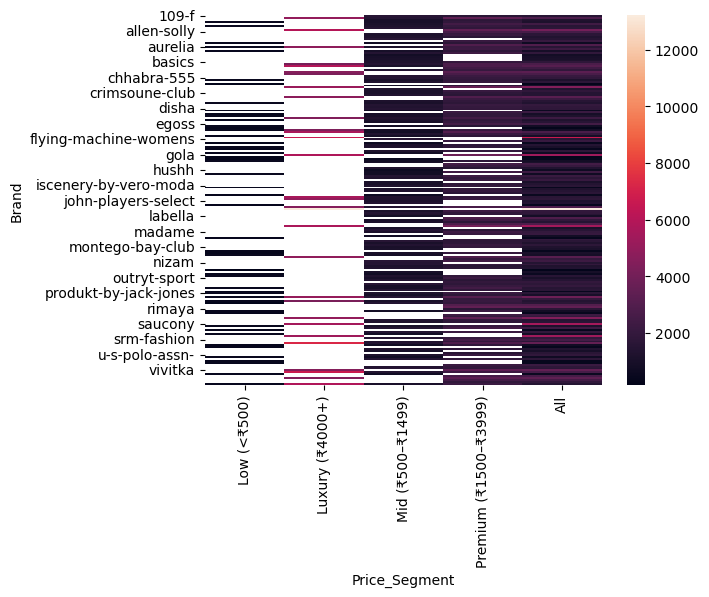

In [36]:
sb.heatmap(a)
plt.show()